# Phân loại sản phẩm đúc bằng CNN, ResNet-18 và MobileNetV2

CNN baseline gồm Conv2D và MaxPooling2D, học từ đầu. ResNet-18 và MobileNetV2
dùng trọng số ImageNet, giữ cố định phần trích xuất đặc trưng và học đầu phân loại.
Ba mô hình được huấn luyện 30 epoch trên cùng danh sách train/validation.

Bộ `casting_data` có 6.633 ảnh train và 715 ảnh test. Giữ nguyên test, loại ảnh train
trùng pixel với test và bản trùng trong train. Validation được tách có phân tầng
từ 15% tập train sau kiểm tra, seed 42. Bộ nguồn đã áp dụng tăng cường dữ liệu;
pipeline của nhóm chỉ tiền xử lý ảnh và giữ nguyên tập test do nguồn cung cấp.

Nhãn **0 = lỗi**, **1 = đạt**. Sigmoid trả `p_ok`, ngưỡng phân loại 0,5.
Checkpoint tốt nhất của từng mô hình được chọn theo validation loss.
Mô hình demo được chọn theo validation loss thấp nhất trong ba mô hình, trước bước đánh giá test.

## 1. Môi trường Colab

Chạy hai ô chuẩn bị thư viện, chọn **Runtime → Restart session**, rồi tiếp tục từ mục 2.
GPU được chọn tại **Runtime → Change runtime type**. CPU cũng chạy được nhưng thời gian huấn luyện dài hơn.

In [1]:
%pip uninstall -y ydf-tf tf-keras keras-nlp

In [2]:
%pip install -q "tensorflow==2.20.0" "keras==3.12.0" "keras-hub==0.23.0" "tensorflow-text==2.20.1" "numpy==2.2.6" "pandas==2.2.3" "scikit-learn==1.6.1" "matplotlib>=3.9,<4" "pillow==11.3.0"


## 2. Thư viện và cấu hình

CNN nhận ảnh xám 256 × 256 × 1. Hai mạng đối chứng nhận ảnh xám lặp thành ba kênh, kích thước 224 × 224.
Mỗi lần thực nghiệm có tên riêng trong `RUN_NAME`.


In [3]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

from pathlib import Path
from datetime import datetime, timezone
import gc
import hashlib
import json
import platform
import shutil
import tempfile
import time
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display
import tensorflow as tf
import keras
from keras import layers
import keras_hub
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

RUN_NAME = "casting_full_3models_01"
OUTPUT_DIR = Path("outputs") / RUN_NAME
DATA_DIR = Path("data/casting_data/casting_data")
IMG_SIZE = (256, 256)
TRANSFER_SIZE = (224, 224)
CLASS_NAMES = ["def_front", "ok_front"]
CLASS_TITLES = ["Lỗi", "Đạt"]
MODEL_NAMES = ["cnn", "resnet18", "mobilenetv2"]
VALIDATION_FRACTION = 0.15
EPOCHS = 30
BATCH_SIZE = 32
LEARNING_RATE = 0.001
SEED = 42
THRESHOLD = 0.5
RESNET_PRESET = "resnet_18_imagenet"

if (tf.__version__, keras.__version__, keras_hub.__version__) != ("2.20.0", "3.12.0", "0.23.0"):
    raise RuntimeError("Phiên bản thư viện chưa đúng. Kiểm tra ô cài đặt và khởi động lại session.")
if np.__version__ != "2.2.6":
    raise RuntimeError("NumPy cần là 2.2.6. Khởi động lại session sau khi cài thư viện.")
keras.utils.set_random_seed(SEED)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
environment = {
    "python": platform.python_version(), "platform": platform.platform(),
    "tensorflow": tf.__version__, "keras": keras.__version__, "keras_hub": keras_hub.__version__,
    "numpy": np.__version__, "gpu": [tf.config.experimental.get_device_details(device).get("device_name", device.name)
                                    for device in tf.config.list_physical_devices("GPU")],
    "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
}
environment_path = OUTPUT_DIR / "environment.json"
if not environment_path.exists():
    environment_path.write_text(json.dumps(environment, indent=2), encoding="utf-8")
print("GPU:", environment["gpu"])
print("Thư mục kết quả:", OUTPUT_DIR.resolve())

GPU: ['Tesla T4']
Thư mục kết quả: /content/outputs/casting_full_3models_01


## 3. Upload dữ liệu

ZIP cần chứa `train/def_front`, `train/ok_front`, `test/def_front`, `test/ok_front`.
Có thể nén thư mục `casting_data` ngoài cùng. Chương trình tìm đúng cấp thư mục bên trong ZIP.

In [4]:
try:
    from google.colab import files
except ImportError:
    files = None

if files is not None:
    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError("Chọn một ZIP dữ liệu.")
    filename, content = next(iter(uploaded.items()))
    archive_path = Path(tempfile.mkdtemp(prefix="casting_upload_")) / Path(filename).name
    archive_path.write_bytes(content)
    del uploaded, content
    if not zipfile.is_zipfile(archive_path):
        raise ValueError("Tệp được chọn cần là ZIP hợp lệ.")
    extract_dir = archive_path.parent / "data"
    extract_dir.mkdir()
    with zipfile.ZipFile(archive_path) as archive:
        for member in archive.infolist():
            if not (extract_dir / member.filename).resolve().is_relative_to(extract_dir.resolve()):
                raise ValueError("ZIP chứa đường dẫn nằm ngoài thư mục dữ liệu.")
        archive.extractall(extract_dir)
    candidates = sorted({
        folder.parent for folder in extract_dir.rglob("train")
        if folder.is_dir() and "__MACOSX" not in folder.parts
        and all((folder.parent / split / label).is_dir()
                for split in ["train", "test"] for label in CLASS_NAMES)
    })
    if not candidates:
        raise FileNotFoundError("ZIP cần chứa đủ train/test và hai lớp. Kiểm tra bộ casting_data.")
    for index, folder in enumerate(candidates):
        print(index, folder)
    choice = 0 if len(candidates) == 1 else int(input("Chọn số thứ tự bộ casting_data: "))
    if not 0 <= choice < len(candidates):
        raise ValueError("Số thứ tự nằm ngoài danh sách.")
    DATA_DIR = candidates[choice]
print("Dữ liệu:", DATA_DIR.resolve())

Saving casting_data.zip to casting_data.zip
0 /tmp/casting_upload_gsh1d65z/data/casting_data
Dữ liệu: /tmp/casting_upload_gsh1d65z/data/casting_data


## 4. Kiểm tra ảnh và chia tập

Giữ nguyên 715 ảnh test. Tách 15% từ tập train sau loại ảnh trùng làm validation, có phân tầng theo lớp.
Ảnh được hiệu chỉnh hướng, chuyển xám và resize bilinear về 256 × 256.
Mã băm pixel trước resize dùng để phát hiện ảnh trùng chính xác. Kiểm tra này chưa xác định
được các biến thể augmentation gần giống nhau; nguồn không cung cấp mã sản phẩm để chia theo nhóm.

In [5]:
records, arrays, seen = [], [], {}
bad_images, duplicates, original_counts, dimensions = [], [], {}, {}
for source_split in ["test", "train"]:
    for label, class_name in enumerate(CLASS_NAMES):
        class_dir = DATA_DIR / source_split / class_name
        if not class_dir.is_dir():
            raise FileNotFoundError(f"Thiếu thư mục {class_dir}")
        paths = sorted(path for path in class_dir.rglob("*")
                       if path.is_file() and path.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"})
        original_counts[f"{source_split}/{class_name}"] = len(paths)
        for path in paths:
            try:
                with Image.open(path) as source:
                    gray = ImageOps.exif_transpose(source).convert("L")
                    digest = hashlib.sha256(str(gray.size).encode() + gray.tobytes()).hexdigest()
                    dimensions[str(gray.size)] = dimensions.get(str(gray.size), 0) + 1
                    resized = gray.resize((IMG_SIZE[1], IMG_SIZE[0]), Image.Resampling.BILINEAR)
                    array = np.asarray(resized, dtype=np.uint8)[..., None]
            except (OSError, ValueError, Image.DecompressionBombError) as error:
                bad_images.append({"path": str(path), "error": str(error)})
                continue
            relative = path.relative_to(DATA_DIR).as_posix()
            if digest in seen:
                kept = seen[digest]
                if kept["label"] != label or source_split == "test":
                    raise ValueError(f"Ảnh trùng khác nhãn hoặc trùng trong test: {relative}")
                duplicates.append({"kept_path": kept["path"], "excluded_train_path": relative,
                                   "label": label, "sha256": digest})
                continue
            seen[digest] = {"path": relative, "label": label}
            records.append({"path": relative, "label": label, "sha256": digest,
                            "source_split": source_split})
            arrays.append(array)

print("Ảnh hỏng:", bad_images[:5], "| Bản trùng đã loại khỏi train:", len(duplicates))
if bad_images:
    raise ValueError("Cần kiểm tra ảnh hỏng trước khi huấn luyện. Xem danh sách vừa in.")
expected_counts = {"train/def_front": 3758, "train/ok_front": 2875,
                   "test/def_front": 453, "test/ok_front": 262}
if original_counts != expected_counts:
    raise ValueError(f"Số ảnh khác bộ casting_data đã chốt: {original_counts}")
images = np.stack(arrays)
labels = np.array([record["label"] for record in records], dtype=np.int32)
del arrays
audit = {"original_counts": original_counts, "valid_images": len(records), "dimensions": dimensions,
         "bad_images": bad_images, "excluded_train_duplicates": duplicates,
         "duplicate_check": "SHA256 pixels before resize; augmented relatives not identified"}
data_counts = pd.DataFrame({"class": CLASS_NAMES,
                            "count": [int(np.sum(labels == label)) for label in [0, 1]]})
display(data_counts)

Ảnh hỏng: [] | Bản trùng đã loại khỏi train: 64


,class,count
0,def_front,4211
1,ok_front,3073


In [6]:
source_train_idx = np.array([i for i, record in enumerate(records) if record["source_split"] == "train"])
test_idx = np.array([i for i, record in enumerate(records) if record["source_split"] == "test"])
train_idx, val_idx = train_test_split(source_train_idx, test_size=VALIDATION_FRACTION,
                                      stratify=labels[source_train_idx], random_state=SEED)
splits = {"train": train_idx, "validation": val_idx, "test": test_idx}
assert len(test_idx) == 715 and len(train_idx) + len(val_idx) == len(source_train_idx)
assert len(val_idx) == int(np.ceil(len(source_train_idx) * VALIDATION_FRACTION))
manifest = {name: [records[int(index)] for index in indices] for name, indices in splits.items()}
manifest_text = json.dumps(manifest, ensure_ascii=False, indent=2)
manifest_sha256 = hashlib.sha256(manifest_text.encode()).hexdigest()
hash_sets = [{record["sha256"] for record in manifest[name]} for name in splits]
assert not (hash_sets[0] & hash_sets[1] or hash_sets[0] & hash_sets[2] or hash_sets[1] & hash_sets[2])
config = {"run_name": RUN_NAME, "method": "ConvCNN_casting_data_official_test_v2", "models": MODEL_NAMES,
          "classes": CLASS_NAMES, "image_size": list(IMG_SIZE), "transfer_size": list(TRANSFER_SIZE),
          "epochs": EPOCHS, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE,
          "seed": SEED, "validation_fraction_of_source_train": VALIDATION_FRACTION,
          "pipeline_augmentation": False, "source_augmentation": True, "official_test_preserved": True,
          "duplicate_policy": "preserve_test_exclude_duplicate_train_before_validation_split",
          "threshold": THRESHOLD, "resnet_preset": RESNET_PRESET, "manifest_sha256": manifest_sha256,
          "demo_selection": "minimum_best_validation_loss"}
config_path = OUTPUT_DIR / "config.json"
if config_path.exists() and json.loads(config_path.read_text(encoding="utf-8")) != config:
    raise ValueError("RUN_NAME đã có cấu hình hoặc dữ liệu khác. Đặt tên lần chạy mới.")
config_path.write_text(json.dumps(config, indent=2), encoding="utf-8")
(OUTPUT_DIR / "split.json").write_text(manifest_text, encoding="utf-8")
(OUTPUT_DIR / "data_check.json").write_text(json.dumps(audit, ensure_ascii=False, indent=2), encoding="utf-8")
data_counts.to_csv(OUTPUT_DIR / "data_counts.csv", index=False)
pd.DataFrame(duplicates, columns=["kept_path", "excluded_train_path", "label", "sha256"]).to_csv(
    OUTPUT_DIR / "excluded_train_duplicates.csv", index=False)
split_counts = pd.DataFrame({name: [int(np.sum(labels[indices] == label)) for label in [0, 1]]
                            for name, indices in splits.items()}, index=CLASS_NAMES)
split_counts.to_csv(OUTPUT_DIR / "split_counts.csv")
for record in manifest["test"]:
    target = OUTPUT_DIR / "demo_test" / Path(record["path"]).relative_to("test")
    target.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(DATA_DIR / record["path"], target)
display(split_counts)
print("Ảnh chọn demo:", (OUTPUT_DIR / "demo_test").resolve())

,train,validation,test
def_front,3194,564,453
ok_front,2389,422,262


Ảnh chọn demo: /content/outputs/casting_full_3models_01/demo_test


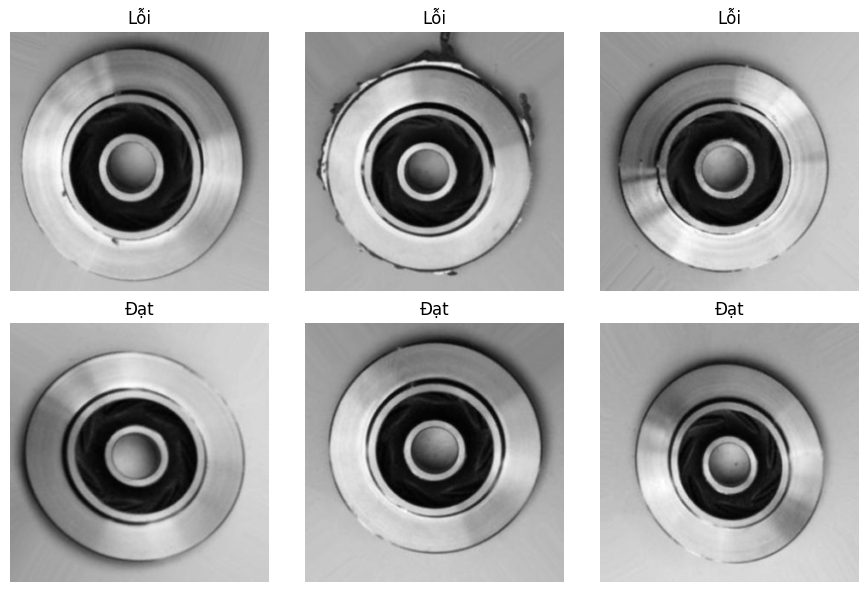

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(9, 6))
for label in [0, 1]:
    positions = train_idx[labels[train_idx] == label][:3]
    for axis, position in zip(axes[label], positions):
        axis.imshow(images[position, ..., 0], cmap="gray")
        axis.set_title(CLASS_TITLES[label])
        axis.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "data_samples.png", dpi=180)
plt.show()


## 5. Pipeline dữ liệu và hàm huấn luyện

Giá trị đầu vào vẫn là 0–255. Chuẩn hóa được đặt trong từng mô hình.
Checkpoint được chọn bằng validation loss thấp nhất trong 30 epoch.


In [8]:
def make_dataset(indices, model_name, training=False):
    targets = labels[indices].astype(np.float32).reshape(-1, 1)
    dataset = tf.data.Dataset.from_tensor_slices((images[indices], targets))
    if training:
        dataset = dataset.shuffle(len(indices), seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.batch(BATCH_SIZE)
    if model_name != "cnn":
        def prepare_transfer(batch, target):
            batch = tf.image.resize(tf.cast(batch, tf.float32), TRANSFER_SIZE, method="bilinear", antialias=True)
            return tf.image.grayscale_to_rgb(batch), target
        dataset = dataset.map(prepare_transfer, num_parallel_calls=tf.data.AUTOTUNE)
    return dataset.prefetch(tf.data.AUTOTUNE)


def compile_model(model):
    model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss="binary_crossentropy",
                  metrics=[keras.metrics.BinaryAccuracy(name="accuracy")], jit_compile=False)
    return model


def classification_head(features):
    features = layers.GlobalAveragePooling2D(name="global_average_pool")(features)
    features = layers.Dense(64, activation="relu", name="dense64")(features)
    features = layers.Dropout(0.3, name="dropout")(features)
    return layers.Dense(1, activation="sigmoid", name="p_ok")(features)


In [9]:
def download_results(prefix):
    zip_path = OUTPUT_DIR.parent / f"{prefix}_{RUN_NAME}.zip"
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
        for path in sorted(OUTPUT_DIR.rglob("*")):
            if path.is_file():
                archive.write(path, arcname=f"{RUN_NAME}/{path.relative_to(OUTPUT_DIR).as_posix()}")
    print("Tệp kết quả:", zip_path.resolve())
    if files is not None:
        files.download(str(zip_path))
    return zip_path

In [10]:
def train_model(model_name, model):
    checkpoint = OUTPUT_DIR / f"{model_name}.keras"
    history_path = OUTPUT_DIR / f"history_{model_name}.csv"
    fit_path = OUTPUT_DIR / f"fit_{model_name}.json"
    if any(path.exists() for path in [checkpoint, history_path, fit_path]):
        raise FileExistsError(f"Đã có tệp của {model_name}. Giữ kết quả hoặc đặt RUN_NAME mới trước khi train lại.")

    summary_lines = []
    model.summary(print_fn=lambda line, **kwargs: summary_lines.append(line), expand_nested=True)
    (OUTPUT_DIR / f"model_summary_{model_name}.txt").write_text("\n".join(summary_lines), encoding="utf-8")
    (OUTPUT_DIR / f"architecture_{model_name}.json").write_text(model.to_json(), encoding="utf-8")
    info = {"model": model_name, "status": "running", "epochs_requested": EPOCHS,
            "seed": SEED, "pipeline_augmentation": False, "source_augmentation": True, "manifest_sha256": manifest_sha256,
            "total_params": int(model.count_params()),
            "trainable_params": int(sum(np.prod(weight.shape) for weight in model.trainable_weights)),
            "started_at_utc": datetime.now(timezone.utc).isoformat()}
    fit_path.write_text(json.dumps(info, indent=2), encoding="utf-8")
    callbacks = [
        keras.callbacks.ModelCheckpoint(str(checkpoint), monitor="val_loss", mode="min", save_best_only=True),
        keras.callbacks.CSVLogger(str(history_path)),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
        keras.callbacks.TerminateOnNaN(),
    ]
    started = time.perf_counter()
    try:
        model.fit(make_dataset(train_idx, model_name, training=True),
                  validation_data=make_dataset(val_idx, model_name), epochs=EPOCHS,
                  callbacks=callbacks, verbose=1)
        history = pd.read_csv(history_path)
        if len(history) != EPOCHS or not np.isfinite(history[["loss", "val_loss", "accuracy", "val_accuracy"]]).all().all():
            raise RuntimeError("Lượt huấn luyện chưa đủ epoch hoặc có loss không hữu hạn.")
        best = history.loc[history["val_loss"].idxmin()]
        info.update(status="completed", epochs_completed=len(history), best_epoch=int(best["epoch"]) + 1,
                    best_validation_loss=float(best["val_loss"]),
                    best_validation_accuracy=float(best["val_accuracy"]),
                    checkpoint_sha256=hashlib.sha256(checkpoint.read_bytes()).hexdigest())
    except BaseException as error:
        info.update(status="interrupted_or_failed", error=str(error))
        raise
    finally:
        info["fit_seconds"] = float(time.perf_counter() - started)
        fit_path.write_text(json.dumps(info, indent=2), encoding="utf-8")
    print("Đã lưu:", checkpoint, "| Epoch chọn:", info["best_epoch"])
    display(history.tail())

## 6. CNN baseline

CNN Conv2D/MaxPooling2D học từ đầu, giữ nguyên kiến trúc đã chốt.

In [11]:
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
cnn_model = keras.Sequential([
    keras.Input(shape=(*IMG_SIZE, 1), name="images"),
    layers.Rescaling(1.0 / 255, name="rescale"),
    layers.Conv2D(32, 3, padding="same", activation="relu", name="conv32"),
    layers.MaxPooling2D(name="pool1"),
    layers.Conv2D(64, 3, padding="same", activation="relu", name="conv64"),
    layers.MaxPooling2D(name="pool2"),
    layers.Conv2D(128, 3, padding="same", activation="relu", name="conv128"),
    layers.MaxPooling2D(name="pool3"),
    layers.GlobalAveragePooling2D(name="global_average_pool"),
    layers.Dense(64, activation="relu", name="dense64"),
    layers.Dropout(0.3, name="dropout"),
    layers.Dense(1, activation="sigmoid", name="p_ok"),
], name="casting_conv_cnn")
compile_model(cnn_model)
cnn_model.summary()


Model: "casting_conv_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescale (Rescaling)             │ (None, 256, 256, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv32 (Conv2D)                 │ (None, 256, 256, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv64 (Conv2D)                 │ (None, 128, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv128 (Conv2D)                │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pool             │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense64 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_ok (Dense)                    │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,993 (394.50 KB)

 Trainable params: 100,993 (394.50 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
train_model("cnn", cnn_model)
del cnn_model
keras.backend.clear_session()
gc.collect()

backup_cnn = download_results("after_cnn")

Epoch 1/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 18s 63ms/step - accuracy: 0.5710 - loss: 0.6864 - val_accuracy: 0.5720 - val_loss: 0.6838 - learning_rate: 0.0010
Epoch 2/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 52ms/step - accuracy: 0.5721 - loss: 0.6827 - val_accuracy: 0.5720 - val_loss: 0.6794 - learning_rate: 0.0010
Epoch 3/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 52ms/step - accuracy: 0.5823 - loss: 0.6694 - val_accuracy: 0.5720 - val_loss: 0.6285 - learning_rate: 0.0010
Epoch 4/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 53ms/step - accuracy: 0.7602 - loss: 0.5228 - val_accuracy: 0.8519 - val_loss: 0.4049 - learning_rate: 0.0010
Epoch 5/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 53ms/step - accuracy: 0.8313 - loss: 0.4263 - val_accuracy: 0.8753 - val_loss: 0.3409 - learning_rate: 0.0010
Epoch 6/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 54ms/step - accuracy: 0.8506 - loss: 0.3899 - val_accuracy: 0.9097 - val_loss: 0.2983 - learning_rate: 0.0010
Epoch 7/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 54ms/step - accuracy: 0.8452 - loss: 0

,epoch,accuracy,loss,val_accuracy,val_loss
25,25,0.935698,0.176923,0.947262,0.174680
26,26,0.937131,0.175947,0.952333,0.137760
27,27,0.933011,0.178812,0.934077,0.165176
28,28,0.943579,0.157045,0.958418,0.121010
29,29,0.940355,0.161781,0.950304,0.136158


Tệp kết quả: /content/outputs/after_cnn_casting_full_3models_01.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. ResNet-18

Phần trích xuất đặc trưng dùng preset `resnet_18_imagenet` của KerasHub và bộ chuyển ảnh từ cùng preset.
Trọng số ImageNet được giữ cố định. Đầu phân loại mới có cùng kiểu lớp với CNN.


In [13]:
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
resnet_inputs = keras.Input(shape=(*TRANSFER_SIZE, 3), name="images")
converter = keras_hub.layers.ResNetImageConverter.from_preset(
    RESNET_PRESET, image_size=TRANSFER_SIZE, crop_to_aspect_ratio=False)
resnet_backbone = keras_hub.models.ResNetBackbone.from_preset(RESNET_PRESET, load_weights=True)
resnet_backbone.trainable = False
resnet_features = resnet_backbone(converter(resnet_inputs), training=False)
resnet_model = compile_model(keras.Model(resnet_inputs, classification_head(resnet_features), name="casting_resnet18"))
resnet_model.summary(expand_nested=True)
(OUTPUT_DIR / "preprocessing_resnet18.json").write_text(json.dumps(converter.get_config(), indent=2), encoding="utf-8")


Model: "casting_resnet18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ images (InputLayer)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ res_net_image_converter         │ (None, 224, 224, 3)    │             0 │
│ (ResNetImageConverter)          │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ res_net_backbone                │ (None, 7, 7, 512)      │    11,186,112 │
│ (ResNetBackbone)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ input_layer (InputLayer)   │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv1_pad (ZeroPadding2D)  │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv1_conv (Conv2D)        │ (None, None, None, 64) │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv1_bn                   │ (None, None, None, 64) │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv1_relu (Activation)    │ (None, None, None, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ pool1_pad (ZeroPadding2D)  │ (None, None, None, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ pool1_pool (MaxPooling2D)  │ (None, None, None, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ stack0_block0_1_conv       │ (None, None, None, 64) │        36,864 │
│ (Conv2D)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ stack0_block0_1_bn         │ (None, None, None, 64) │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ stack0_block0_1_relu       │ (None, None, None, 64) │             0 │
│ (Activation)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ stack0_block0_2_conv       │ (None, None, None, 64) │        36,864 │
│ (Conv2D)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ stack0_block0_2_bn         │ (None, None, None, 64) │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ stack0_block0_add (Add)    │ (None, None, None, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ stack0_block0_out          │ (None, None, None, 64) │             0 │
│ (Activation)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ stack0_block1_1_conv       │ (None, None, None, 64) │        36,864 │
│ (Conv2D)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ stack0_block1_1_bn         │ (None, None, None, 64) │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 11,219,009 (42.80 MB)

 Trainable params: 32,897 (128.50 KB)

 Non-trainable params: 11,186,112 (42.67 MB)

586

In [14]:
train_model("resnet18", resnet_model)
del resnet_model, resnet_backbone, converter, resnet_inputs, resnet_features
keras.backend.clear_session()
gc.collect()

backup_resnet18 = download_results("after_resnet18")

Epoch 1/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 35s 172ms/step - accuracy: 0.8216 - loss: 0.4422 - val_accuracy: 0.9544 - val_loss: 0.2464 - learning_rate: 0.0010
Epoch 2/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 29s 163ms/step - accuracy: 0.9527 - loss: 0.1844 - val_accuracy: 0.9716 - val_loss: 0.1281 - learning_rate: 0.0010
Epoch 3/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 39s 152ms/step - accuracy: 0.9701 - loss: 0.1153 - val_accuracy: 0.9726 - val_loss: 0.0923 - learning_rate: 0.0010
Epoch 4/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 41s 153ms/step - accuracy: 0.9778 - loss: 0.0852 - val_accuracy: 0.9767 - val_loss: 0.0772 - learning_rate: 0.0010
Epoch 5/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 41s 150ms/step - accuracy: 0.9819 - loss: 0.0676 - val_accuracy: 0.9797 - val_loss: 0.0586 - learning_rate: 0.0010
Epoch 6/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 28s 157ms/step - accuracy: 0.9828 - loss: 0.0584 - val_accuracy: 0.9807 - val_loss: 0.0524 - learning_rate: 0.0010
Epoch 7/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 39s 150ms/step - accuracy: 0.9

,epoch,accuracy,loss,val_accuracy,val_loss
25,25,0.995701,0.016500,0.985801,0.028836
26,26,0.995701,0.016183,0.985801,0.027897
27,27,0.995701,0.014864,0.987830,0.027085
28,28,0.996239,0.014305,0.987830,0.026946
29,29,0.996059,0.014411,0.988844,0.029461


Tệp kết quả: /content/outputs/after_resnet18_casting_full_3models_01.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. MobileNetV2

MobileNetV2 dùng alpha = 1,0 và trọng số ImageNet. Đầu vào được đổi về miền −1 đến 1 trong mô hình.
Phần trích xuất đặc trưng được giữ cố định, phần Dense mới được học trong 30 epoch.


In [15]:
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
mobile_inputs = keras.Input(shape=(*TRANSFER_SIZE, 3), name="images")
mobile_scaled = layers.Rescaling(1.0 / 127.5, offset=-1.0, name="preprocessing")(mobile_inputs)
mobile_backbone = keras.applications.MobileNetV2(include_top=False, weights="imagenet", input_shape=(*TRANSFER_SIZE, 3), alpha=1.0)
mobile_backbone.trainable = False
mobile_features = mobile_backbone(mobile_scaled, training=False)
mobile_model = compile_model(keras.Model(mobile_inputs, classification_head(mobile_features), name="casting_mobilenetv2"))
mobile_model.summary(expand_nested=True)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "casting_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ images (InputLayer)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocessing (Rescaling)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ input_layer (InputLayer)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ Conv1 (Conv2D)             │ (None, 112, 112, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ bn_Conv1                   │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ Conv1_relu (ReLU)          │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ expanded_conv_depthwise    │ (None, 112, 112, 32)   │           288 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ expanded_conv_depthwise_BN │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └                            │ (None, 112, 112, 32)   │             0 │
│ expanded_conv_depthwise_relu    │                        │               │
│ (ReLU)                          │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ expanded_conv_project      │ (None, 112, 112, 16)   │           512 │
│ (Conv2D)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ expanded_conv_project_BN   │ (None, 112, 112, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ block_1_expand (Conv2D)    │ (None, 112, 112, 96)   │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ block_1_expand_BN          │ (None, 112, 112, 96)   │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ block_1_expand_relu (ReLU) │ (None, 112, 112, 96)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ block_1_pad                │ (None, 113, 113, 96)   │             0 │
│ (ZeroPadding2D)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ block_1_depthwise          │ (None, 56, 56, 96)     │           864 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ block_1_depthwise_BN       │ (None, 56, 56, 96)     │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ block_1_depthwise_relu     │ (None, 56, 56, 96)     │             

 Total params: 2,340,033 (8.93 MB)

 Trainable params: 82,049 (320.50 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [16]:
train_model("mobilenetv2", mobile_model)
del mobile_model, mobile_backbone, mobile_inputs, mobile_scaled, mobile_features
keras.backend.clear_session()
gc.collect()

backup_mobilenetv2 = download_results("after_mobilenetv2")

Epoch 1/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 26s 118ms/step - accuracy: 0.9095 - loss: 0.2380 - val_accuracy: 0.9726 - val_loss: 0.0923 - learning_rate: 0.0010
Epoch 2/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 17s 96ms/step - accuracy: 0.9807 - loss: 0.0710 - val_accuracy: 0.9838 - val_loss: 0.0515 - learning_rate: 0.0010
Epoch 3/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 17s 95ms/step - accuracy: 0.9893 - loss: 0.0459 - val_accuracy: 0.9899 - val_loss: 0.0401 - learning_rate: 0.0010
Epoch 4/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 20s 90ms/step - accuracy: 0.9914 - loss: 0.0330 - val_accuracy: 0.9888 - val_loss: 0.0496 - learning_rate: 0.0010
Epoch 5/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 17s 95ms/step - accuracy: 0.9923 - loss: 0.0279 - val_accuracy: 0.9919 - val_loss: 0.0274 - learning_rate: 0.0010
Epoch 6/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 17s 94ms/step - accuracy: 0.9921 - loss: 0.0276 - val_accuracy: 0.9868 - val_loss: 0.0375 - learning_rate: 0.0010
Epoch 7/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 21s 96ms/step - accuracy: 0.9939 - 

,epoch,accuracy,loss,val_accuracy,val_loss
25,25,0.996597,0.008508,0.994929,0.015555
26,26,0.997671,0.007583,0.993915,0.015360
27,27,0.998388,0.004745,0.994929,0.015239
28,28,0.998388,0.004673,0.994929,0.016163
29,29,0.997492,0.004587,0.993915,0.017893


Tệp kết quả: /content/outputs/after_mobilenetv2_casting_full_3models_01.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Lựa chọn mô hình và đánh giá

Mô hình demo được chọn từ ba checkpoint theo validation loss thấp nhất.
Sau khi lưu lựa chọn, từng checkpoint được đánh giá trên cùng 715 ảnh test.
Kết quả test phục vụ báo cáo chất lượng phân loại của các cấu hình đã cố định.

In [17]:
fit_records = {}
for model_name in MODEL_NAMES:
    fit = json.loads((OUTPUT_DIR / f"fit_{model_name}.json").read_text(encoding="utf-8"))
    if fit["status"] != "completed" or fit["epochs_completed"] != EPOCHS:
        raise RuntimeError(f"Lượt {model_name} chưa hoàn tất 30 epoch.")
    assert fit["manifest_sha256"] == manifest_sha256
    if not np.isfinite(fit["best_validation_loss"]):
        raise ValueError(f"Validation loss không hợp lệ: {model_name}")
    checkpoint = OUTPUT_DIR / f"{model_name}.keras"
    assert hashlib.sha256(checkpoint.read_bytes()).hexdigest() == fit["checkpoint_sha256"]
    fit_records[model_name] = fit
selected_model = min(MODEL_NAMES, key=lambda name: fit_records[name]["best_validation_loss"])
selection = {"model": selected_model, "criterion": "minimum_best_validation_loss",
             "best_epoch": fit_records[selected_model]["best_epoch"],
             "validation_loss": fit_records[selected_model]["best_validation_loss"],
             "manifest_sha256": manifest_sha256,
             "checkpoint_sha256": fit_records[selected_model]["checkpoint_sha256"],
             "candidates": {name: fit_records[name]["best_validation_loss"] for name in MODEL_NAMES}}
(OUTPUT_DIR / "selection.json").write_text(json.dumps(selection, indent=2), encoding="utf-8")
display(pd.DataFrame([{"model": name, "best_validation_loss": fit_records[name]["best_validation_loss"],
                       "selected_for_demo": name == selected_model} for name in MODEL_NAMES]))

,model,best_validation_loss,selected_for_demo
0,cnn,0.121010,False
1,resnet18,0.026946,False
2,mobilenetv2,0.015027,True


In [18]:
def save_evaluation_figures(model_name, history, matrix, predicted, p_ok):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    epochs = history["epoch"] + 1
    for axis, metric in zip(axes, ["loss", "accuracy"]):
        axis.plot(epochs, history[metric], label="Train")
        axis.plot(epochs, history[f"val_{metric}"], label="Validation")
        axis.set(xlabel="Epoch", ylabel=metric, title=model_name)
        axis.legend()
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"learning_curves_{model_name}.png", dpi=180)
    plt.show()
    display_matrix = ConfusionMatrixDisplay(matrix, display_labels=CLASS_TITLES)
    display_matrix.plot(cmap="Blues", values_format="d")
    display_matrix.ax_.set(xlabel="Nhãn dự đoán", ylabel="Nhãn thật", title=model_name)
    display_matrix.figure_.tight_layout()
    display_matrix.figure_.savefig(OUTPUT_DIR / f"confusion_matrix_{model_name}.png", dpi=180)
    plt.show()
    correct = np.flatnonzero(predicted == labels[test_idx])[:3]
    incorrect = np.flatnonzero(predicted != labels[test_idx])[:3]
    fig, axes = plt.subplots(2, 3, figsize=(10, 7))
    for row, positions in enumerate([correct, incorrect]):
        for axis in axes[row]:
            axis.axis("off")
        for axis, position in zip(axes[row], positions):
            axis.imshow(images[test_idx[position], ..., 0], cmap="gray")
            axis.set_title(f"Thật: {CLASS_TITLES[labels[test_idx[position]]]} | Dự đoán: {CLASS_TITLES[predicted[position]]}\np_ok={p_ok[position]:.4f}", fontsize=9)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"examples_{model_name}.png", dpi=180)
    plt.show()


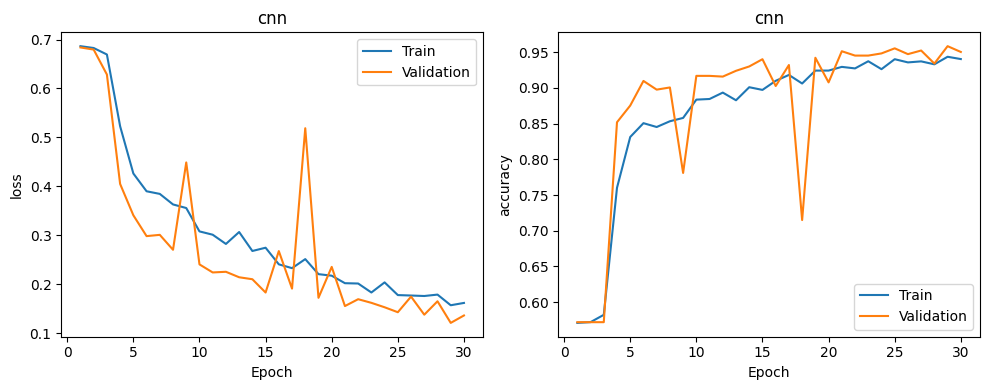

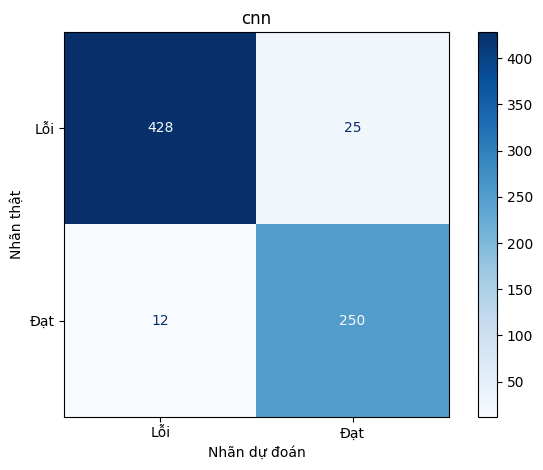

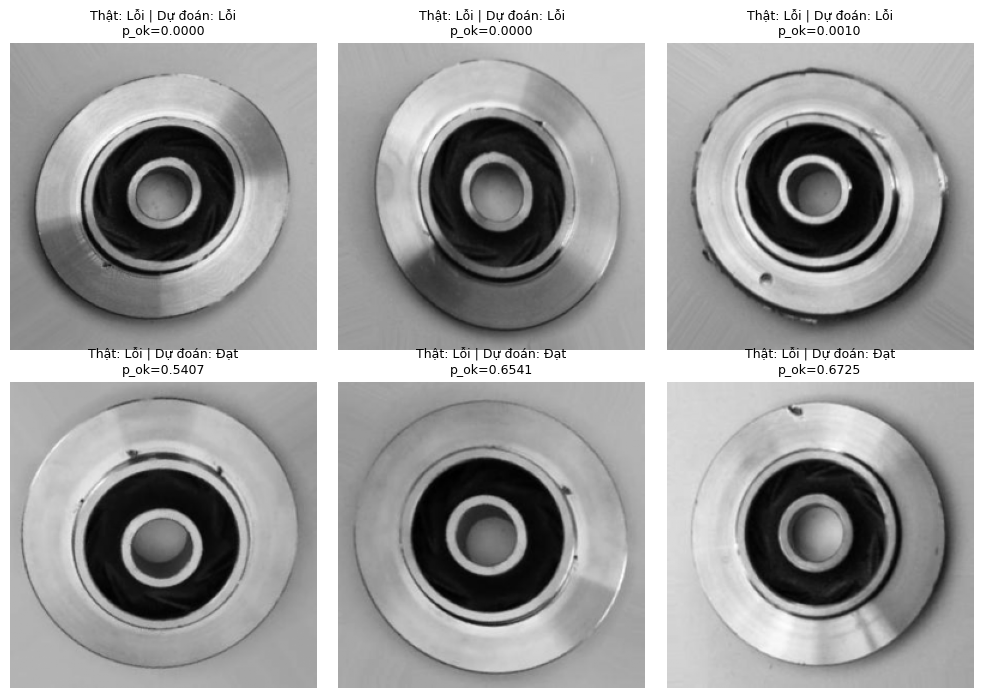

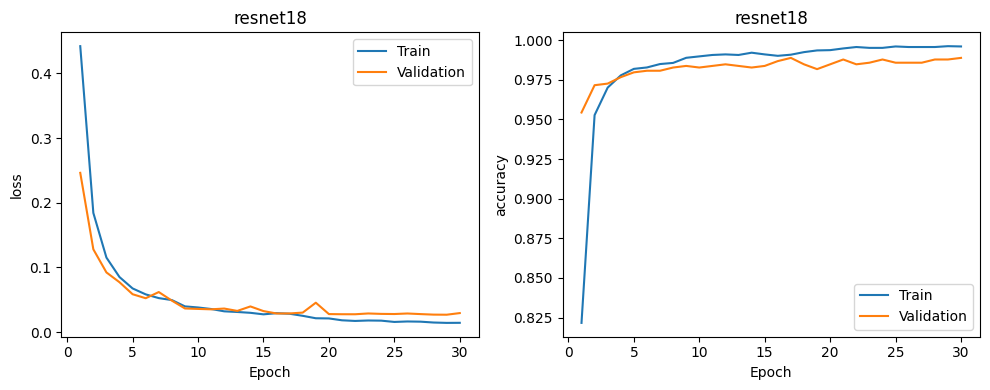

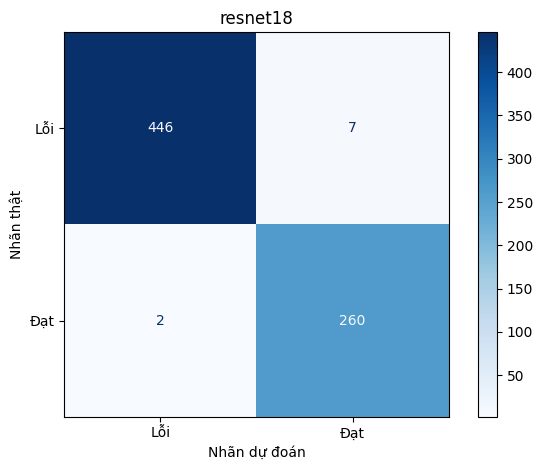

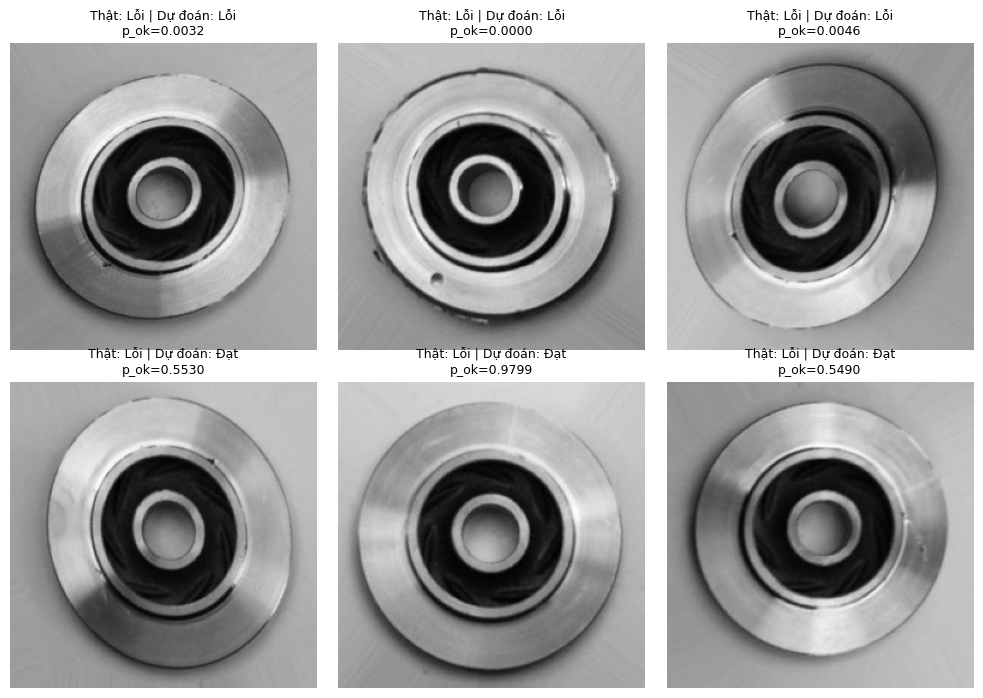

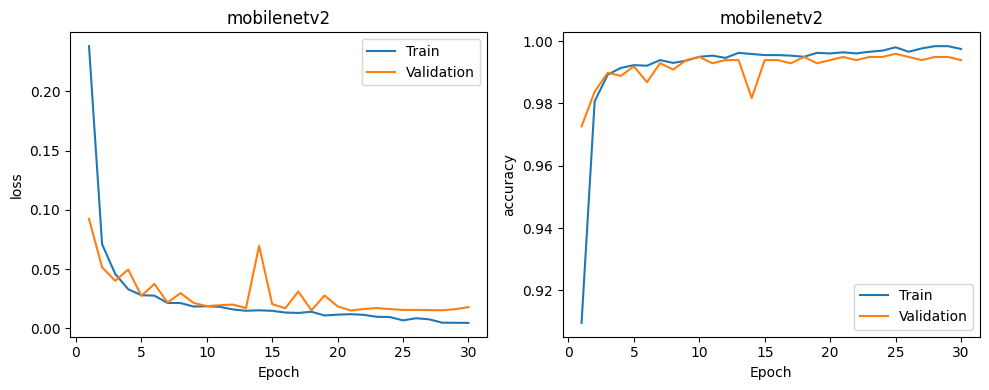

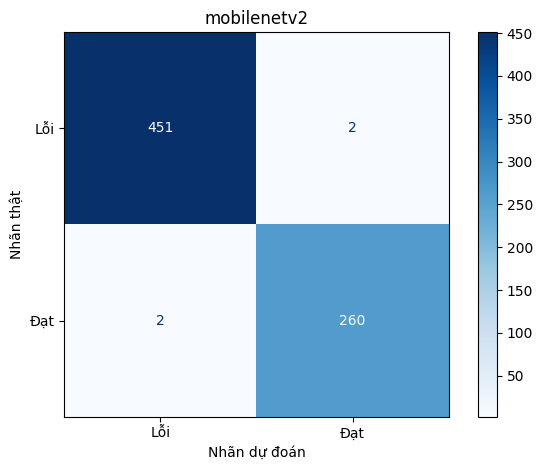

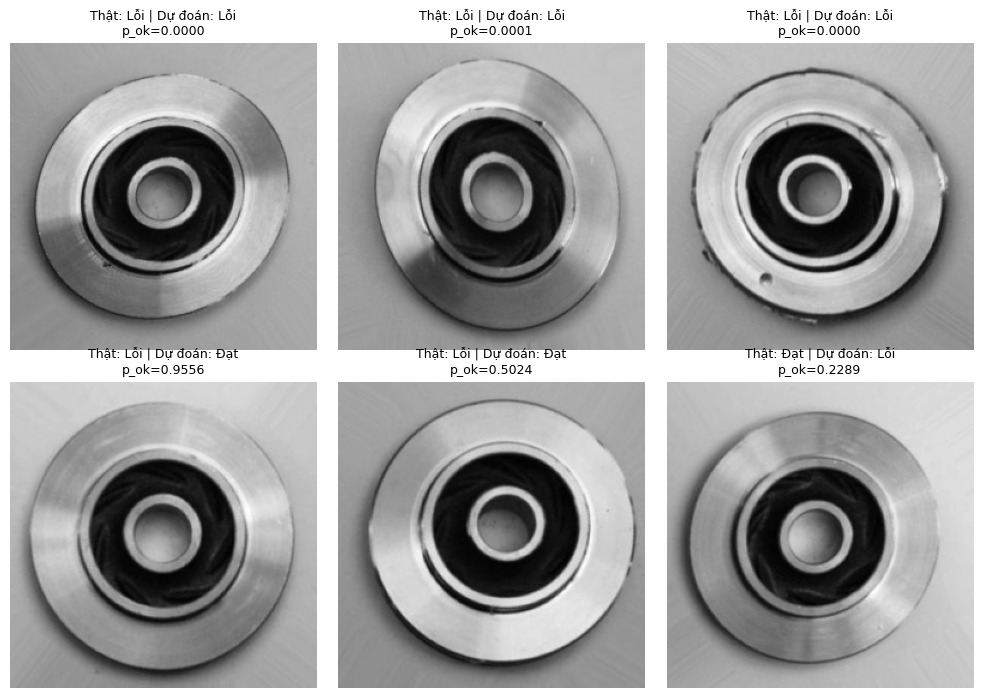

In [19]:
comparison_rows = []
for model_name in MODEL_NAMES:
    fit = json.loads((OUTPUT_DIR / f"fit_{model_name}.json").read_text(encoding="utf-8"))
    if fit["status"] != "completed" or fit["epochs_completed"] != EPOCHS:
        raise RuntimeError(f"Lượt {model_name} chưa hoàn tất.")
    assert fit["manifest_sha256"] == manifest_sha256
    checkpoint = OUTPUT_DIR / f"{model_name}.keras"
    assert hashlib.sha256(checkpoint.read_bytes()).hexdigest() == fit["checkpoint_sha256"]
    history = pd.read_csv(OUTPUT_DIR / f"history_{model_name}.csv")
    candidate = keras.models.load_model(checkpoint, compile=False)
    candidate.jit_compile = False  # Tắt XLA khi dự đoán để hỗ trợ resize bicubic của ResNet.
    p_ok = candidate.predict(make_dataset(test_idx, model_name), verbose=0).reshape(-1)
    assert p_ok.shape == (len(test_idx),) and np.isfinite(p_ok).all()
    assert ((p_ok >= 0) & (p_ok <= 1)).all()
    predicted = (p_ok >= THRESHOLD).astype(int)
    truth = labels[test_idx]
    report = classification_report(truth, predicted, labels=[0, 1], target_names=CLASS_NAMES, zero_division=0, output_dict=True)
    matrix = confusion_matrix(truth, predicted, labels=[0, 1])
    metrics = {"model": model_name, "checkpoint_sha256": fit["checkpoint_sha256"], "threshold": THRESHOLD, "test_count": len(test_idx),
               "class_order": CLASS_NAMES, "classification_report": report, "confusion_matrix": matrix.tolist()}
    (OUTPUT_DIR / f"metrics_{model_name}.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
    (OUTPUT_DIR / f"classification_report_{model_name}.txt").write_text(
        classification_report(truth, predicted, labels=[0, 1], target_names=CLASS_NAMES, zero_division=0), encoding="utf-8")
    predictions = pd.DataFrame({"path": [records[int(index)]["path"] for index in test_idx],
                                "true": truth, "predicted": predicted, "p_ok": p_ok, "p_defect": 1 - p_ok})
    predictions.to_csv(OUTPUT_DIR / f"test_predictions_{model_name}.csv", index=False)
    predictions[predictions["true"] != predictions["predicted"]].to_csv(OUTPUT_DIR / f"errors_{model_name}.csv", index=False)
    comparison_rows.append({"model": model_name, "best_epoch": fit["best_epoch"],
        "validation_loss": fit["best_validation_loss"], "accuracy": report["accuracy"],
        "precision_defect": report["def_front"]["precision"], "recall_defect": report["def_front"]["recall"],
        "f1_defect": report["def_front"]["f1-score"], "macro_f1": report["macro avg"]["f1-score"],
        "defect_missed": int(matrix[0, 1]), "false_alarm": int(matrix[1, 0]),
        "total_params": fit["total_params"], "trainable_params": fit["trainable_params"], "fit_seconds": fit["fit_seconds"]})
    save_evaluation_figures(model_name, history, matrix, predicted, p_ok)
    if model_name == selected_model:
        reference_prob = candidate.predict(make_dataset(val_idx[:10], model_name), verbose=0).reshape(-1)
        assert reference_prob.shape == (10,) and np.isfinite(reference_prob).all()
        assert ((reference_prob >= 0) & (reference_prob <= 1)).all()
        reference = {"records": [records[int(index)] for index in val_idx[:10]],
                     "model": model_name, "manifest_sha256": manifest_sha256, "p_ok": reference_prob.tolist(), "checkpoint_sha256": fit["checkpoint_sha256"]}
        (OUTPUT_DIR / "validation_reference_demo.json").write_text(json.dumps(reference, indent=2), encoding="utf-8")
    del candidate
    keras.backend.clear_session()
    gc.collect()

In [20]:
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(OUTPUT_DIR / "comparison.csv", index=False)
display(comparison)


,model,best_epoch,validation_loss,accuracy,precision_defect,recall_defect,f1_defect,macro_f1,defect_missed,false_alarm,total_params,trainable_params,fit_seconds
0,cnn,29,0.121010,0.948252,0.972727,0.944812,0.958567,0.944833,25,12,100993,100993,300.363481
1,resnet18,29,0.026946,0.987413,0.995536,0.984547,0.990011,0.986499,7,2,11219009,32897,990.967286
2,mobilenetv2,21,0.015027,0.994406,0.995585,0.995585,0.995585,0.993976,2,2,2340033,82049,557.113169


## 10. Tải bản sao kết quả và trọng số

Gói này chứa cả ba checkpoint `.keras`, lịch sử, hình và số liệu. Tải về trước khi tiếp tục chuẩn bị demo.


In [21]:
training_zip = download_results("training")

Tệp kết quả: /content/outputs/training_casting_full_3models_01.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Chuẩn bị mô hình demo và kiểm chứng

Checkpoint được chọn theo validation loss được sao chép thành `casting_classifier.keras`.
Ảnh demo được chuyển xám và resize về 256 × 256 như dữ liệu đã đọc khi huấn luyện.
Với ResNet-18/MobileNetV2, tiếp tục resize bilinear có antialias bằng TensorFlow về 224 × 224
và lặp thành ba kênh. Chuẩn hóa theo mô hình đã được tích hợp trong checkpoint.
Mô hình được nạp lại trên CPU và đối chiếu xác suất, nhãn trên 10 ảnh validation.

In [22]:
def prepare_demo_image(source, model_name):
    gray = ImageOps.exif_transpose(source).convert("L")
    resized = gray.resize((IMG_SIZE[1], IMG_SIZE[0]), Image.Resampling.BILINEAR)
    array = np.asarray(resized, dtype=np.float32)[..., None]
    if model_name != "cnn":
        with tf.device("/CPU:0"):
            array = tf.image.resize(array, TRANSFER_SIZE, method="bilinear", antialias=True)
            array = tf.image.grayscale_to_rgb(array).numpy()
    return gray, array

In [23]:
demo_dir = OUTPUT_DIR / "demo"
demo_dir.mkdir(exist_ok=True)
selection = json.loads((OUTPUT_DIR / "selection.json").read_text(encoding="utf-8"))
selected_model = selection["model"]
reference = json.loads((OUTPUT_DIR / "validation_reference_demo.json").read_text(encoding="utf-8"))
assert reference["model"] == selected_model and reference["manifest_sha256"] == manifest_sha256
source_model = OUTPUT_DIR / f"{selected_model}.keras"
assert hashlib.sha256(source_model.read_bytes()).hexdigest() == reference["checkpoint_sha256"]
model_path = demo_dir / "casting_classifier.keras"
shutil.copyfile(source_model, model_path)
input_size = IMG_SIZE if selected_model == "cnn" else TRANSFER_SIZE
channels = 1 if selected_model == "cnn" else 3
metadata = {"model_format": "keras", "model_file": model_path.name, "model": selected_model,
            "run_name": RUN_NAME, "manifest_sha256": manifest_sha256,
            "model_sha256": hashlib.sha256(model_path.read_bytes()).hexdigest(),
            "selection": selection, "classes": CLASS_NAMES, "image_size": list(input_size),
            "channels": channels, "input_layout": "NHWC", "input_dtype": "float32",
            "input_range": [0, 255], "output_meaning": "p_ok", "threshold": THRESHOLD,
            "preprocessing": {"exif_transpose": True, "color": "PIL grayscale L",
                              "base_resize": list(IMG_SIZE), "base_interpolation": "PIL bilinear",
                              "transfer_resize": list(TRANSFER_SIZE) if channels == 3 else None,
                              "transfer_interpolation": "tf.image.resize bilinear antialias=True",
                              "repeat_grayscale_channels": channels == 3,
                              "normalization": "included in model"}, "verification": None}
(demo_dir / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
check_images = []
for record in reference["records"]:
    with Image.open(DATA_DIR / record["path"]) as source:
        gray = ImageOps.exif_transpose(source).convert("L")
        digest = hashlib.sha256(str(gray.size).encode() + gray.tobytes()).hexdigest()
        assert digest == record["sha256"], f"Ảnh khác bản đã dùng: {record['path']}"
        check_images.append(prepare_demo_image(source, selected_model)[1])
check_batch = np.stack(check_images)
with tf.device("/CPU:0"):
    demo_model = keras.models.load_model(model_path, compile=False)
    assert tuple(demo_model.input_shape[1:]) == (*input_size, channels)
    actual_prob = demo_model(check_batch, training=False).numpy().reshape(-1)
expected_prob = np.asarray(reference["p_ok"])
assert actual_prob.shape == expected_prob.shape == (10,)
assert np.isfinite(actual_prob).all() and np.isfinite(expected_prob).all()
assert ((actual_prob >= 0) & (actual_prob <= 1)).all()
np.testing.assert_allclose(actual_prob, expected_prob, rtol=1e-3, atol=1e-4, equal_nan=False)
np.testing.assert_array_equal(actual_prob >= THRESHOLD, expected_prob >= THRESHOLD)
verification = {"images": 10, "labels_agree": True, "rtol": 1e-3, "atol": 1e-4,
                "max_probability_error": float(np.max(np.abs(actual_prob - expected_prob)))}
metadata["verification"] = verification
(demo_dir / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
(demo_dir / "verification.json").write_text(json.dumps(verification, indent=2), encoding="utf-8")
pd.DataFrame({"path": [record["path"] for record in reference["records"]],
              "p_ok_reference": expected_prob, "p_ok_demo": actual_prob,
              "absolute_error": np.abs(actual_prob - expected_prob)}).to_csv(demo_dir / "verification.csv", index=False)
print("Mô hình demo:", selected_model, "| Kiểm chứng CPU:", verification)
del demo_model
keras.backend.clear_session()
gc.collect()

Mô hình demo: mobilenetv2 | Kiểm chứng CPU: {'images': 10, 'labels_agree': True, 'rtol': 0.001, 'atol': 0.0001, 'max_probability_error': 4.21423465013504e-08}


0

## 12. Demo nhanh một ảnh

Upload một ảnh trong `demo_test/def_front` hoặc `demo_test/ok_front` đã tải về ở mục 10.
Có thể thử ảnh ngoài bộ dữ liệu khi điều kiện chụp tương tự. Mỗi lần chạy lưu một hình và tệp JSON.

Saving cast_ok_0_45.jpeg to cast_ok_0_45.jpeg
Dự đoán: Đạt
Xác suất lỗi: 0.18% | Xác suất đạt: 99.82%


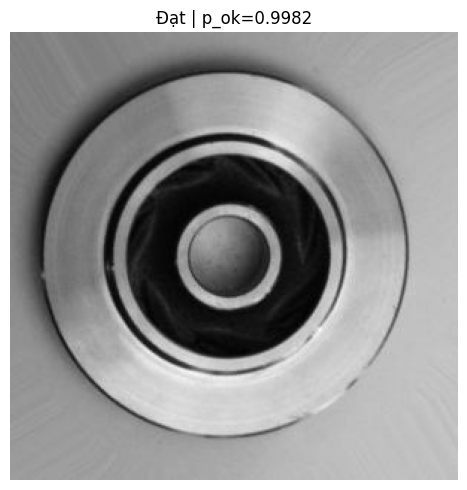

0

In [26]:
from io import BytesIO

assert metadata.get("verification") and metadata["verification"]["labels_agree"], "Cần hoàn tất mục 11 trước."
if files is not None:
    uploaded_image = files.upload()
    if len(uploaded_image) != 1:
        raise ValueError("Chọn một ảnh để dự đoán.")
    image_name, image_bytes = next(iter(uploaded_image.items()))
    image_source = BytesIO(image_bytes)
else:
    image_name = "anh_demo.jpeg"
    image_source = DATA_DIR / image_name

with Image.open(image_source) as source:
    demo_image, prepared = prepare_demo_image(source, metadata["model"])
input_batch = prepared[None, ...]
assert hashlib.sha256(model_path.read_bytes()).hexdigest() == metadata["model_sha256"]
with tf.device("/CPU:0"):
    loaded_model = keras.models.load_model(model_path, compile=False)
    probability_ok = float(loaded_model(input_batch, training=False).numpy()[0, 0])
assert np.isfinite(probability_ok) and 0 <= probability_ok <= 1
predicted_label = int(probability_ok >= THRESHOLD)
print("Dự đoán:", CLASS_TITLES[predicted_label])
print(f"Xác suất lỗi: {1 - probability_ok:.2%} | Xác suất đạt: {probability_ok:.2%}")
fig, axis = plt.subplots(figsize=(5, 5))
axis.imshow(demo_image, cmap="gray")
axis.set_title(f"{CLASS_TITLES[predicted_label]} | p_ok={probability_ok:.4f}")
axis.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "demo_prediction.png", dpi=180)
plt.show()
(OUTPUT_DIR / "demo_prediction.json").write_text(json.dumps({
    "image": image_name, "model": metadata["model"], "predicted_label": predicted_label, "p_ok": probability_ok,
    "model_sha256": metadata["model_sha256"],
}, ensure_ascii=False, indent=2), encoding="utf-8")
del loaded_model
keras.backend.clear_session()
gc.collect()

## 13. Tải gói demo và kết quả cuối cùng

`demo_bundle.zip` chứa mô hình đã chọn, metadata và kết quả kiểm chứng.
`complete_*.zip` chứa toàn bộ trọng số, hình, số liệu và ảnh test để chọn demo.
Sau khi chạy, tải notebook kèm output và cả gói complete về máy để cập nhật báo cáo.

In [25]:
metadata = json.loads((demo_dir / "metadata.json").read_text(encoding="utf-8"))
assert metadata["verification"]["labels_agree"] and metadata["verification"]["images"] == 10
assert hashlib.sha256((demo_dir / "casting_classifier.keras").read_bytes()).hexdigest() == metadata["model_sha256"]
demo_zip = OUTPUT_DIR / "demo_bundle.zip"
with zipfile.ZipFile(demo_zip, "w", zipfile.ZIP_DEFLATED) as archive:
    for filename in ["casting_classifier.keras", "metadata.json", "verification.json", "verification.csv"]:
        archive.write(demo_dir / filename, arcname=filename)
print("Gói demo:", demo_zip.resolve())
if files is not None:
    files.download(str(demo_zip))
complete_zip = download_results("complete")

Gói demo: /content/outputs/casting_full_3models_01/demo_bundle.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Tệp kết quả: /content/outputs/complete_casting_full_3models_01.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Tài liệu tham khảo

- Bộ ảnh Casting Product Image Data for Quality Inspection, Ravirajsinh Dabhi, Kaggle.
  https://www.kaggle.com/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product
- KerasHub ResNetBackbone và ResNetImageConverter.
  https://keras.io/keras_hub/api/models/resnet/resnet_backbone/
  https://keras.io/keras_hub/api/models/resnet/resnet_image_converter/
- Keras MobileNetV2 và lưu mô hình.
  https://keras.io/api/applications/mobilenet/mobilenet_models/
  https://keras.io/guides/serialization_and_saving/

Các nhận xét kết quả được bổ sung sau khi chạy thực nghiệm. Báo cáo cần sử dụng các tệp của cùng `RUN_NAME`.
